Tempo de treinamento (Árvore de Decisão): 0.1149 segundos
Tempo de treinamento (Random Forest): 0.4628 segundos


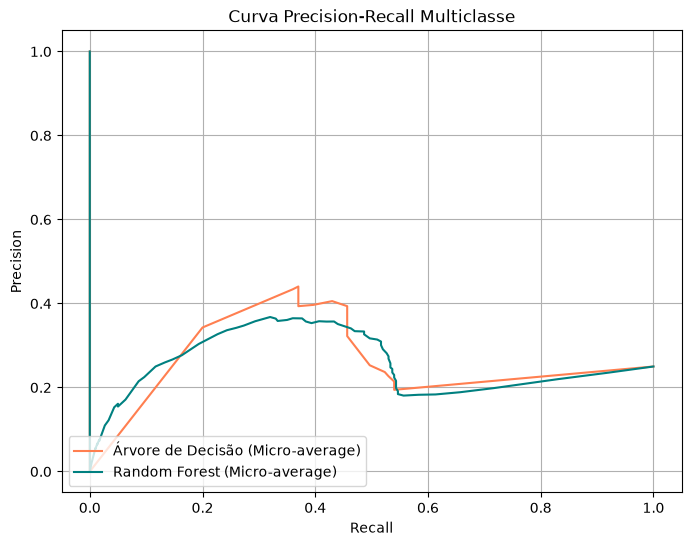

In [2]:
import pandas as pd
import time
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import label_binarize
from sklearn.metrics import precision_recall_curve

# 1. Carregar dados de classificação
train_cls = pd.read_csv('../data/processed/train_classification.csv')
test_cls = pd.read_csv('../data/processed/test_classification.csv')
target_col_cls = train_cls.columns[-1]

X_train_c, y_train_c = train_cls.drop(columns=[target_col_cls]), train_cls[target_col_cls]
X_test_c, y_test_c = test_cls.drop(columns=[target_col_cls]), test_cls[target_col_cls]

# 2. Modelos
dt_clf = DecisionTreeClassifier(max_depth=3, random_state=42)
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)

# 3. Medição de Tempo de Treinamento (Wall-clock)
def medir_treino(modelo, X, y, nome):
    inicio = time.perf_counter()
    modelo.fit(X, y)
    fim = time.perf_counter()
    print(f"Tempo de treinamento ({nome}): {fim - inicio:.4f} segundos")
    return modelo

dt_clf = medir_treino(dt_clf, X_train_c, y_train_c, "Árvore de Decisão")
rf_clf = medir_treino(rf_clf, X_train_c, y_train_c, "Random Forest")

# 4. Geração das Curvas PR-AUC (Multiclasse - Micro-Average)
classes = y_train_c.unique()
y_test_bin = label_binarize(y_test_c, classes=classes)

dt_probs = dt_clf.predict_proba(X_test_c)
rf_probs = rf_clf.predict_proba(X_test_c)

precision_dt, recall_dt, _ = precision_recall_curve(y_test_bin.ravel(), dt_probs.ravel())
precision_rf, recall_rf, _ = precision_recall_curve(y_test_bin.ravel(), rf_probs.ravel())

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(recall_dt, precision_dt, label="Árvore de Decisão (Micro-average)", color="coral")
ax.plot(recall_rf, precision_rf, label="Random Forest (Micro-average)", color="teal")

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Curva Precision-Recall Multiclasse")
ax.legend(loc="lower left")
ax.grid(True)

plt.savefig('../reports/figures/pr_auc_curve.png', bbox_inches='tight')
plt.show()